# Lab 6: From scraping books to crawling a link graph
**Information Retrieval & Web Analytics · CADT · Week 6 · 3 hours**  
**Student version — complete the TODO cells, remove their `raise NotImplementedError(...)` lines, and write the Answer prompts.**

In Week 5 you scraped **Books to Scrape** with Beautiful Soup and built the `bookcrawler` Scrapy project. You followed `li.next a` and used `parse_book()` to extract a book's description. Today you keep the same website and extraction selectors, but make scheduling explicit: **seed → frontier → fetch → parse → normalize links → queue unseen URLs → stop**.

| Week 5 skill or artifact | How you extend it today |
|---|---|
| `urljoin(page_url, href)` | Normalize URLs before duplicate detection |
| Two-page pagination loop | A FIFO frontier with depth and request limits |
| `article.product_pod h3 a`, `li.next a` | Discover book pages and the next listing |
| `div.product_main h1`, `#product_description + p` | Reuse detail extraction for the IR corpus |
| `doc_id, title, text, url, category, source` | Keep the same six corpus fields |
| `bookcrawler` and `response.follow()` | Explain Scrapy's scheduler and duplicate filter |
| `ir_books_corpus.jsonl` | Compare today's small sample with last week's export |

**Outcomes:** implement bounded breadth-first crawling; distinguish discovered/queued/attempted/saved pages; explain traps; export a corpus and directed link graph; interpret degrees, reachability and components without confusing missing observations with real dangling pages.

**Pacing (180 min):** reconnect/setup 15 · normalization 20 · extraction 15 · BFS 40 · break 10 · limits/traps 15 · export/QA 20 · graph 25 · reflection 10. Focused crawling, indexing and Scrapy extensions are optional/homework.

**Core boundary:** at most **2 listing URLs**, **6 detail URLs**, **8 HTML request attempts**, depth **2**. Robots is checked separately. Do not crawl all 1,000 books. Internet is required for the live sample; offline exercises still run. The site's prices and ratings are dummy data.

## Part 0. Reconnect with Week 5 (15 min)
Keep this notebook beside your Week 5 files if possible. Your old exports are helpful but **not required**; this notebook includes the imports and helper scaffolds you need.

Install missing packages in the notebook environment only if needed:
```python
%pip install requests beautifulsoup4 pandas matplotlib networkx
```
Do not rerun the live crawl to experiment with limits: later experiments use saved responses. Keep the same two-page boundary as Week 5. Check robots at runtime; a missing robots file does not replace reviewing site terms.

In [1]:
from pathlib import Path
from collections import deque, Counter, defaultdict
from urllib.parse import urljoin, urldefrag, urlsplit, urlunsplit, parse_qsl, urlencode
from urllib import robotparser
import hashlib, json, re, time, heapq
from datetime import datetime, timezone
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

BASE = "https://books.toscrape.com/"
SEED = BASE
USER_AGENT = "CADT-IR-Lab6/1.0 (educational sandbox crawler)"
HEADERS = {"User-Agent": USER_AGENT}
DELAY_SECONDS = 0.5
OUTPUT = Path("lab6_output")
OUTPUT.mkdir(exist_ok=True)
print("Same site as Week 5:", BASE)

Same site as Week 5: https://books.toscrape.com/


### Provided: robots and a cached, polite downloader
Read the helper, then use it unchanged. It checks robots before each HTML fetch; requests have timeouts, delays and no automatic redirects. A redirect must be reviewed rather than silently leaving our scope. A 403 or 429 stops the run. A failed attempt still consumes budget.

`live_fetch()` returns `None` for a robots block, a transport error, an HTTP error, or non-HTML. The BFS function will count every call in `attempted`, so this is a conservative upper bound on actual HTML network requests. `fetch_stats` gives network/error counts. Cached successful responses allow later experiments without new requests.

In [2]:
# Run once before the live crawl. This cell makes ONE robots request.
robots_response = requests.get(urljoin(BASE, "robots.txt"), headers=HEADERS,
                               timeout=20, allow_redirects=False)
rp = robotparser.RobotFileParser()
if robots_response.status_code == 200:
    rp.parse(robots_response.text.splitlines())
    robots_exists = True
elif robots_response.status_code == 404:
    robots_exists = False
else:
    raise RuntimeError(f"Cannot verify robots rules: HTTP {robots_response.status_code}")

def is_allowed(url):
    return (not robots_exists) or rp.can_fetch(USER_AGENT, url)

effective_delay = max(DELAY_SECONDS, (rp.crawl_delay(USER_AGENT) or 0) if robots_exists else 0)
# Include the robots request in the delay before our next network request.
last_request_end = time.monotonic()
response_cache = {}
fetch_stats = Counter()

def live_fetch(url):
    global last_request_end
    if url in response_cache:
        fetch_stats["cache_hits"] += 1
        return response_cache[url]
    if urlsplit(url)[:2] != urlsplit(BASE)[:2] or not is_allowed(url):
        fetch_stats["scope_or_robots_blocked"] += 1
        return None
    time.sleep(max(0, effective_delay - (time.monotonic() - last_request_end)))
    fetch_stats["network_requests"] += 1
    try:
        response = requests.get(url, headers=HEADERS, timeout=20, allow_redirects=False)
    except requests.RequestException as exc:
        fetch_stats["transport_errors"] += 1
        print(type(exc).__name__, url)
        return None
    finally:
        last_request_end = time.monotonic()
    fetch_stats[f"http_{response.status_code}"] += 1
    if response.status_code in (403, 429):
        raise RuntimeError(f"Stop: HTTP {response.status_code}; review access/Retry-After before any retry.")
    if response.status_code != 200:
        return None
    if "text/html" not in response.headers.get("Content-Type", "").lower():
        fetch_stats["non_html"] += 1
        return None
    response_cache[url] = response
    return response

print("robots HTTP:", robots_response.status_code, "| effective delay:", effective_delay)
print("Seed allowed:", is_allowed(SEED))

robots HTTP: 404 | effective delay: 0.5
Seed allowed: True


**Answer 0.1:** Week 5 already followed links. What new scheduling decisions become visible when you replace its pagination loop with a frontier? Which six fields must today's book corpus preserve?

*Your answer:*

## Part 1. Normalize before checking duplicates (20 min)
Reuse `urljoin`, then remove fragments, lowercase the scheme/host, and remove **only** query keys `utm` and `utm_*`. Keep meaningful keys such as `page`, `id`, `lang`; keep the path's case. Return `None` for non-HTTP(S) URLs or URLs with credentials.

For **this site**, treat `/index.html` as an alias of `/`. Do not collapse a detail path such as `/catalogue/book_123/index.html`. This is an explicit site rule, not a universal rule. Query-bearing URLs are tested below, but are excluded from this lab's live crawl.

In [6]:
def normalize_url(href, page_url):
    """Canonical absolute URL, or None for unsupported links."""
    # TODO 1: resolve relative href; urldefrag; split; validate scheme/credentials.
    absolute_url = urljoin(page_url, href)
    absolute_url = urldefrag(absolute_url).url
    parts = urlsplit(absolute_url)
    
    # Validate scheme
    if parts.scheme.lower() not in ("http", "https"):
        return None
    
    # Validate hostname
    if not parts.hostname:
        return None
    
    if parts.username is not None or parts.password is not None:
        return None
    
    # TODO 2: remove only tracking keys; rebuild query withx urlencode(...).
    tracking_keys = {"utm","fbclid", "gclid", "msclkid"}

    filtered_params = [
        (key, value)
        for key, value in parse_qsl(parts.query, keep_blank_values=True)
        if not key.lower().startswith("utm_")
        and key.lower() not in tracking_keys
    ]

    clean_query = urlencode(filtered_params)
    # TODO 3: lowercase scheme/netloc; empty path -> "/"; root /index.html -> "/".
    scheme = parts.scheme.lower()
    netloc = parts.netloc.lower()
    path = parts.path or "/"

    if path == "/index.html":
        path = "/"

    return urlunsplit((scheme, netloc, path, clean_query, ""))
    # raise NotImplementedError("Implement normalize_url")

In [7]:
tests = [
    ("catalogue/book_1/index.html#reviews", BASE, BASE + "catalogue/book_1/index.html"),
    ("../book_2/index.html?utm_source=nav", BASE + "catalogue/book_1/index.html", BASE + "catalogue/book_2/index.html"),
    ("/catalogue/page-2.html?page=2&utm=x&lang=km", BASE, BASE + "catalogue/page-2.html?page=2&lang=km"),
    ("HTTPS://BOOKS.TOSCRAPE.COM/index.html#top", BASE, BASE),
    ("/catalogue/MixedCase/index.html", BASE, BASE + "catalogue/MixedCase/index.html"),
    ("mailto:reader@example.org", BASE, None),
]
for href, current, expected in tests:
    actual = normalize_url(href, current)
    assert actual == expected, (href, actual, expected)
print("Normalization checks passed.")

# Provided: narrow scope for this exercise, not all same-host URLs.
def page_kind(url):
    if not url:
        return None
    p = urlsplit(url)
    if p.scheme != "https" or p.netloc != "books.toscrape.com" or p.query:
        return None
    if p.path in ("/", "/catalogue/page-2.html"):
        return "listing"
    if re.fullmatch(r"/catalogue/[^/]+/index\.html", p.path):
        return "book"
    return None
assert page_kind(BASE + "catalogue/page-3.html") is None
assert page_kind(BASE + "catalogue/category/books/poetry_23/index.html") is None

Normalization checks passed.


**Answer 1.1:** Why is removing every query parameter unsafe? Why do we normalize **before** adding a URL to `seen`? Explain why detail-page `/index.html` must remain in the URL.

*Your answer:* Removing every query parameter is unsafe because some parameters contain important information, such as page numbers, search queries, or language settings. Removing them could cause different pages to be treated as the same URL.

We normalize URLs before adding them to seen to ensure that different URL formats pointing to the same page are recognized as duplicates. This prevents unnecessary crawling and improves efficiency.

Detail-page **/index.html** must remain because it identifies a specific book page, while only the root **/index.html** is normalized to **/**. Removing it from detail pages could change the URL's meaning, break links, or cause incorrect page identification.

## Part 2. Reuse Week 5 extraction (15 min)
The downloader gets HTML; these functions only parse it. You may adapt your Week 5 solution. Work from response bytes to let Beautiful Soup read the HTML encoding.

For the teaching graph, record all in-scope `a[href]` links (including breadcrumbs), using visible anchor text as a label. The same selector policy applies to every saved page. For scheduling, use the quotas below; recording an edge does **not** mean requesting its target.

In [8]:
def extract_links(soup, page_url):
    """Return unique (normalized_target, anchor_text) pairs in HTML order."""
    # TODO 2.1: iterate soup.select("a[href]"); normalize; retain page_kind != None.
    # Deduplicate targets within this source page while keeping first occurrence.
    links = []
    seen_targets = set()

    for a in soup.select("a[href]"):
        href = a.get("href")
        target = normalize_url(href, page_url)

        # Keep only URLs within our crawling scope
        if page_kind(target) is None:
            continue

        # Avoid duplicate targets from the same source page
        if target in seen_targets:
            continue

        seen_targets.add(target)

        anchor_text = a.get_text(" ", strip=True)
        links.append((target, anchor_text))

    return links

def parse_book(soup, url):
    """Week 5-compatible six-field IR document; no HTTP requests here."""
    # TODO 2.2: title from div.product_main h1; description from #product_description + p.
    # Category: ul.breadcrumb li:nth-child(3) a; use "" for a missing field.
    # doc_id = hashlib.sha1(url.encode("utf-8")).hexdigest()[:12]
    # text = title + "\n" + description (strip outer whitespace).
    # Return doc_id, title, text, url, category, source="books.toscrape.com".
    
    # Extract title
    title_tag = soup.select_one("div.product_main h1")
    title = title_tag.get_text(strip=True) if title_tag else ""

    # Extract description
    description_tag = soup.select_one("#product_description + p")
    description = (
        description_tag.get_text(" ", strip=True)
        if description_tag else ""
    )

    # Extract category
    category_tag = soup.select_one("ul.breadcrumb li:nth-child(3) a")
    category = category_tag.get_text(strip=True) if category_tag else ""

    # Generate unique document ID
    doc_id = hashlib.sha1(url.encode("utf-8")).hexdigest()[:12]

    # Combine title and description for IR
    text = (title + "\n" + description).strip()

    return {
        "doc_id": doc_id,
        "title": title,
        "text": text,
        "url": url,
        "category": category,
        "source": "books.toscrape.com"
    }

In [9]:
# Tiny offline check: missing description is permitted, navigation must not become IR text.
fixture = BeautifulSoup("""<html><div class="product_main"><h1>Sample Book</h1></div>
<ul class="breadcrumb"><li>Home</li><li>Books</li><li><a>Poetry</a></li></ul>
<a href="../../index.html">Home</a><a href="../../index.html#top">Home again</a>
<a href="mailto:help@example.org">Email</a></html>""", "html.parser")
fixture_url = BASE + "catalogue/sample_1/index.html"
doc = parse_book(fixture, fixture_url)
assert doc["title"] == "Sample Book" and doc["text"] == "Sample Book"
assert doc["category"] == "Poetry"
assert len(extract_links(fixture, fixture_url)) == 1
print("Extraction checks passed.")

Extraction checks passed.


## Part 3. Build the breadth-first crawler (40 min)
**Run one live crawl only.** FIFO means process URLs in order of discovery, at nondecreasing depth. Enqueue the normalized seed at depth 0 and mark it seen immediately.

Use these separate collections:

| Collection/counter | Meaning |
|---|---|
| `frontier` | queued `(url, depth)` pairs |
| `seen` | URLs admitted to frontier, including seed |
| `attempted` | every call to `fetch`, including unsuccessful calls |
| `pages` | successfully downloaded HTML page snapshots |
| `books` | structured IR documents from successful **book** pages only |
| `edges` | unique source/target links observed in saved HTML |
| `queued_counts` | admissions by page type, including seed |

Two listing admissions and six book admissions bound the whole run. Count admissions **when enqueueing**, so failed requests cannot free slots for extra URLs. `max_requests` counts attempts rather than successes. Robots is handled by `fetch`, outside this loop. The fixed scope includes only `/`, `/catalogue/page-2.html` and direct book paths.

**Algorithm:** dequeue → attempt fetch → skip failure → save page/extract book → record all observed in-scope edges → admit unseen links if depth/type quotas permit → repeat until frontier empty or request budget used. A link rejected by depth is not marked seen, so a later shallower route could admit it. Record links even at the depth boundary, but do not expand beyond it.

In [10]:
def crawl(seed, fetch, max_requests=8, max_depth=2, max_listings=2, max_books=6):
    """Return pages, edges, books, stats; fetch is live_fetch or a cached replay."""
    if min(max_requests, max_listings) < 1 or min(max_depth, max_books) < 0:
        raise ValueError("Invalid crawl limits")
    seed = normalize_url(seed, seed)
    if page_kind(seed) != "listing":
        raise ValueError("Use an allowed listing seed")
    frontier = deque([(seed, 0)])
    seen = {seed}
    queued_counts = Counter(listing=1, book=0)
    attempted, pages, books, edges = [], {}, {}, set()
    stats = Counter()
    # TODO 3: implement the loop described above.
    # while frontier and len(attempted) < max_requests:
    #   url, depth = frontier.popleft(); attempted.append(url)
    #   response = fetch(url); if None: count failed_or_blocked and continue
    #   soup = BeautifulSoup(response.content, "html.parser")
    #   save pages[url] = {"url":url, "title":..., "depth":depth,
    #                      "kind":page_kind(url), "text":soup.get_text(" ", strip=True)}
    #   if kind == "book": books[url] = parse_book(soup, url)
    #   for target, anchor in extract_links(soup, url):
    #       edges.add((url, target))  # record BEFORE deciding whether to enqueue
    #       if target in seen: count duplicates_avoided; continue
    #       if depth + 1 > max_depth: count depth_skipped; continue
    #       kind = page_kind(target); limit = max_listings if listing else max_books
    #       if queued_counts[kind] >= limit: count quota_skipped; continue
    #       seen.add(target); queued_counts[kind] += 1; frontier.append((target, depth+1))
    # raise NotImplementedError("Implement bounded FIFO traversal")
    while frontier and len(attempted) < max_requests:

        # Step 1: Dequeue the next URL
        url, depth = frontier.popleft()
        attempted.append(url)

        # Step 2: Fetch the page
        response = fetch(url)

        if response is None:
            stats["failed_or_blocked"] += 1
            continue

        # Step 3: Parse the HTML
        soup = BeautifulSoup(response.content, "html.parser")
        kind = page_kind(url)
  
        title_tag = soup.select_one("title")
        title = title_tag.get_text(" ", strip=True) if title_tag else ""

        # Step 4: Save the downloaded page
        pages[url] = {
            "url": url,
            "title": title,
            "depth": depth,
            "kind": kind,
            "text": soup.get_text(" ", strip=True)
        }

        # Step 5: Extract book documents
        if kind == "book":
            books[url] = parse_book(soup, url)

        # Step 6: Record links and enqueue eligible targets
        for target, anchor in extract_links(soup, url):

            # Record the graph edge before scheduling
            edges.add((url, target))

            # Avoid duplicate admissions
            if target in seen:
                stats["duplicates_avoided"] += 1
                continue

            # Check depth limit
            if depth + 1 > max_depth:
                stats["depth_skipped"] += 1
                continue

            # Check page-type quota
            target_kind = page_kind(target)

            limit = (
                max_listings
                if target_kind == "listing"
                else max_books
            )

            if queued_counts[target_kind] >= limit:
                stats["quota_skipped"] += 1
                continue

            # Admit URL to the frontier
            seen.add(target)
            queued_counts[target_kind] += 1
            frontier.append((target, depth + 1))
    stats.update(attempts=len(attempted), saved_pages=len(pages), books=len(books),
                 queued=len(seen), frontier_remaining=len(frontier))
    return pages, sorted(edges), books, stats

In [11]:
# After implementing the TODO, run ONCE. A clean successful run saves 2 listings + 6 books.
CRAWLED_AT = datetime.now(timezone.utc).isoformat()
pages, edges, books, stats = crawl(SEED, live_fetch)
print("Crawl:", dict(stats), "| downloader:", dict(fetch_stats))
assert stats["attempts"] <= 8
assert len(books) <= 6
assert sum(p["kind"] == "listing" for p in pages.values()) <= 2
page_table = pd.DataFrame(list(pages.values()))
if len(page_table):
    display(page_table[["url", "kind", "depth", "title"]])
else:
    print("No HTML saved. Inspect robots/network results before continuing.")

Crawl: {'duplicates_avoided': 23, 'quota_skipped': 34, 'attempts': 8, 'saved_pages': 8, 'books': 6, 'queued': 8, 'frontier_remaining': 0} | downloader: {'network_requests': 8, 'http_200': 8}


,url,kind,depth,title
0,https://books.toscrape.com/,listing,0,All products | Books to Scrape - Sandbox
1,https://books.toscrape.com/catalogue/a-light-i...,book,1,A Light in the Attic | Books to Scrape - Sandbox
2,https://books.toscrape.com/catalogue/tipping-t...,book,1,Tipping the Velvet | Books to Scrape - Sandbox
3,https://books.toscrape.com/catalogue/soumissio...,book,1,Soumission | Books to Scrape - Sandbox
4,https://books.toscrape.com/catalogue/sharp-obj...,book,1,Sharp Objects | Books to Scrape - Sandbox
5,https://books.toscrape.com/catalogue/sapiens-a...,book,1,Sapiens: A Brief History of Humankind | Books ...
6,https://books.toscrape.com/catalogue/the-requi...,book,1,The Requiem Red | Books to Scrape - Sandbox
7,https://books.toscrape.com/catalogue/page-2.html,listing,1,All products | Books to Scrape - Sandbox


**Answer 3.1:** Trace the first four removals from your frontier. Why can the second listing be processed after several detail pages even though it is also at depth 1?

*Your answer:* The first four URLs removed from the frontier are:
1. Homepage (depth 0) – the initial seed URL.
2. A Light in the Attic (depth 1) – the first discovered book.
3. Tipping the Velvet (depth 1) – the second discovered book.
4. Soumission (depth 1) – the third discovered book.
The second listing page is processed after several book detail pages because BFS uses a FIFO (First-In, First-Out) queue. Although these pages are all at depth 1, they are processed in the order they were discovered and added to the frontier. BFS guarantees nondecreasing depth, not priority based on page type.

**Answer 3.2:** If a detail request returns 404, does it count against the request budget? Is it a saved page or an IR document? Why might your count be below 8 pages/6 books?

*Your answer:* A detail request returning HTTP 404 still counts toward the request budget because the crawler records every fetch attempt, regardless of whether it succeeds. However, a failed request is not saved as an HTML page or an IR document. The total may be below 8 pages or 6 books because of failed requests, robots.txt restrictions, or insufficient eligible URLs.

In our experiment, all 8 requests returned HTTP 200, resulting in 8 saved pages (2 listings and 6 book pages) and 6 IR documents. This confirms that our crawler successfully reached the configured limits without any failed requests.

## Break (10 min)

## Part 4. Limits and traps without extra live requests (15 min)
Replay only the responses from Part 3. A cache miss means **not observed in this sample**, not a 404. These comparisons cover a small captured subgraph, not the entire site. Never fill a cache miss by calling `live_fetch` here.

In [12]:
replay_misses = Counter()
def replay_fetch(url):
    if url not in response_cache:
        replay_misses[url] += 1
    return response_cache.get(url)

rows = []
for depth, budget in [(0, 8), (1, 8), (2, 4), (2, 8)]:
    replay_misses.clear()
    p, e, b, s = crawl(SEED, replay_fetch, max_depth=depth, max_requests=budget)
    rows.append({"depth limit": depth, "attempt budget": budget,
                 "attempts": s["attempts"], "saved HTML": len(p), "book docs": len(b),
                 "cache misses": sum(replay_misses.values())})
display(pd.DataFrame(rows))

,depth limit,attempt budget,attempts,saved HTML,book docs,cache misses
0,0,8,1,1,0,0
1,1,8,8,8,6,0
2,2,4,4,4,3,0
3,2,8,8,8,6,0


In [13]:
# Offline spider trap: every synthetic calendar page exposes a fresh next URL.
# No HTTP requests occur. A seen set cannot stop an infinite chain of UNIQUE URLs.
def calendar_trap(request_budget):
    frontier, seen, trace = deque([1]), {1}, []
    while frontier and len(trace) < request_budget:
        month = frontier.popleft()
        trace.append(f"https://example.invalid/events?month={month}")
        next_month = month + 1
        if next_month not in seen:
            seen.add(next_month)
            frontier.append(next_month)
    return trace, len(frontier)

trace, remaining = calendar_trap(5)
print(*trace, sep="\n")
print("Frontier still contains", remaining, "URL(s) when the budget stops us.")

https://example.invalid/events?month=1
https://example.invalid/events?month=2
https://example.invalid/events?month=3
https://example.invalid/events?month=4
https://example.invalid/events?month=5
Frontier still contains 1 URL(s) when the budget stops us.


**Answer 4.1:** Does `seen` stop the synthetic calendar? Explain the difference between a duplicate loop and infinitely many unique URLs. Name two limits that can stop a trap.

*Your answer:* No, **seen** cannot stop the synthetic calendar because each generated URL contains a unique month parameter. The **seen** set only prevents revisiting previously discovered URLs. A duplicate loop repeatedly visits the same URLs, while an infinite chain continuously generates new URLs that have never been seen.
Two limits that can stop this trap are request budget (max_requests) and crawl depth (max_depth). In our experiment, the request budget stopped the crawler after 5 URLs, even though one URL remained in the frontier.

**Answer 4.2:** Why can cached replay not tell us how many pages are reachable on the whole book site? Which limits apply to book documents versus HTTP attempts?

*Your answer:* Cached replay cannot determine how many pages are reachable across the entire book website because it only uses responses saved during the original crawl. A cache miss means the page was not observed in our sample, not that it does not exist.

The max_books limit controls how many book URLs can be admitted for crawling, while max_requests limits the total number of HTTP fetch attempts, including failed requests. Additionally, max_listings limits listing-page admissions, and max_depth restricts how far the crawler can explore.

Therefore, the number of saved book documents may be smaller than the book admission limit, depending on successful downloads and the request budget.

## Part 5. Save and compare the IR corpus (20 min)
Save both crawl evidence and search documents. `pages.jsonl` contains page snapshots (listings **and** details); `edges.csv` records links; `ir_books_corpus.jsonl` contains **only book documents**, with the same six fields as Week 5. Navigation text belongs in the snapshot, not in book search text. All outputs go under `lab6_output/` to preserve last week's files.

In [14]:
FIELDS = ["doc_id", "title", "text", "url", "category", "source"]
# TODO 5.1: save pages.values() as UTF-8 JSONL to OUTPUT / "pages.jsonl".
with open(OUTPUT / "pages.jsonl", "w", encoding="utf-8") as f:
    for page in pages.values():
        f.write(json.dumps(page, ensure_ascii=False) + "\n")
# TODO 5.2: save edges as CSV with source,target headers, using pandas or csv.writer.
edges_df = pd.DataFrame(edges, columns=["source", "target"])
edges_df.to_csv(OUTPUT / "edges.csv", index=False)
# TODO 5.3: save only FIELDS from books.values() to OUTPUT / "ir_books_corpus.jsonl".
with open(OUTPUT / "ir_books_corpus.jsonl", "w", encoding="utf-8") as f:
    for book in books.values():
        document = {field: book[field] for field in FIELDS}
        f.write(json.dumps(document, ensure_ascii=False) + "\n")

# TODO 5.4: save crawl_metadata.json with seed, CRAWLED_AT, scope, limits,
#           effective_delay, robots status, stats and fetch_stats.
metadata = {
    "seed": SEED,
    "crawled_at": CRAWLED_AT,
    "scope": {
        "domain": "books.toscrape.com",
        "allowed_kinds": ["listing", "book"],
        "allowed_listing_paths": ["/", "/catalogue/page-2.html"],
        "book_path_pattern": r"/catalogue/[^/]+/index\.html"
    },
    "limits": {
        "max_requests": 8,
        "max_depth": 2,
        "max_listings": 2,
        "max_books": 6
    },
    "effective_delay": DELAY_SECONDS,
    "robots_status": "See live_fetch robots configuration",
    "stats": dict(stats),
    "fetch_stats": dict(fetch_stats)
}

with open(OUTPUT / "crawl_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

print("All files saved successfully!")
# raise NotImplementedError("Export crawl evidence and corpus")

All files saved successfully!


In [16]:
corpus_path = OUTPUT / "ir_books_corpus.jsonl"
records = [json.loads(line) for line in corpus_path.read_text(encoding="utf-8").splitlines() if line.strip()]
assert records, "No documents: investigate the crawl instead of fabricating records."
assert all(set(row) == set(FIELDS) for row in records)
assert len({r["doc_id"] for r in records}) == len(records)
assert len({r["url"] for r in records}) == len(records)
print("Documents:", len(records))
print("Empty titles:", sum(not r["title"].strip() for r in records))
print("Empty text:", sum(not r["text"].strip() for r in records))
print("Title-only documents:", sum(r["text"].strip() == r["title"].strip() for r in records))
display(pd.DataFrame(records)[["doc_id", "title", "category"]])

# Optional comparison: update the path if your Week 5 export is elsewhere.
week5_path = Path("../W5/ir_books_corpus.jsonl")
if week5_path.exists():
    old = {r["url"]: r for r in map(json.loads, filter(str.strip, week5_path.read_text(encoding="utf-8").splitlines()))}
    shared = [r for r in records if r["url"] in old]
    print("Shared URLs with Week 5:", len(shared))
    display(pd.DataFrame([{"url": r["url"], "same title": r["title"] == old[r["url"]]["title"]} for r in shared]))
else:
    print("Week 5 export absent: core lab still works; compare its six-field schema manually.")

Documents: 6
Empty titles: 0
Empty text: 0
Title-only documents: 0


,doc_id,title,category
0,b828157e0e87,A Light in the Attic,Poetry
1,d21e642d904a,Tipping the Velvet,Historical Fiction
2,bee79c49893a,Soumission,Fiction
3,be802d47518e,Sharp Objects,Mystery
4,c065fb933121,Sapiens: A Brief History of Humankind,History
5,6e35640b1d28,The Requiem Red,Young Adult


Shared URLs with Week 5: 6


,url,same title
0,https://books.toscrape.com/catalogue/a-light-i...,True
1,https://books.toscrape.com/catalogue/tipping-t...,True
2,https://books.toscrape.com/catalogue/soumissio...,True
3,https://books.toscrape.com/catalogue/sharp-obj...,True
4,https://books.toscrape.com/catalogue/sapiens-a...,True
5,https://books.toscrape.com/catalogue/the-requi...,True


**Answer 5.1:** Week 5's Scrapy crawl aimed for about 40 books; this crawl has at most 6. Why is this expected? If a shared book's title differs, what would you inspect before deciding which parser is wrong?

*Your answer:* This is expected because Week 6 uses a bounded BFS crawler with strict limits of 8 HTTP requests, 6 book admissions, 2 listing admissions, and a maximum depth of 2. In contrast, Week 5's Scrapy crawler aimed to collect approximately 40 books by exploring more pages.
If a shared book's title differs, I would first inspect the original HTML, the CSS selectors used by both parsers, URL normalization, and possible changes in the website's content or encoding before concluding that either parser is incorrect.
In our results, all 6 shared books have matching titles, confirming that the Week 6 title extraction is consistent with Week 5 for these documents.

## Part 6. Read the observed link graph (25 min)
A link from page A to page B is directed **A → B**. Build two graphs:

- `G`: every saved source plus every discovered target, even if the target was not downloaded.
- `H`: the subgraph containing only successfully downloaded pages and edges between them.

Degrees count unique page-to-page links, not repeated anchor tags. In-degree measures observed incoming links; out-degree measures observed outgoing links. A highly linked page is a potential **authority**; a hub points to many pages. Observed degrees alone do not establish global importance.

A target-only node has observed out-degree zero because we did not fetch its HTML. Even a fetched page with no eligible links may have links excluded by our scope. Call these **observed sinks**, and avoid claiming they are true Web-wide dangling pages. Components and reachability also describe only the graph you built.

In [17]:
# TODO 6.1: make nx.DiGraph G; add all pages as nodes, then all edges.
# Add attribute fetched=(url in pages) for each node.
G = nx.DiGraph()

# Add all successfully downloaded pages
G.add_nodes_from(pages.keys())

# Add all observed links
# NetworkX automatically adds target nodes that do not exist yet
G.add_edges_from(edges)

# Mark whether each node was successfully downloaded
nx.set_node_attributes(
    G,
    {url: url in pages for url in G.nodes},
    "fetched"
)
# TODO 6.2: H = G.subgraph(pages).copy()
H = G.subgraph(pages.keys()).copy()
# raise NotImplementedError("Build observed and fetched-page graphs")

Observed graph: 42 nodes; 64 edges
Fetched-only graph: 8 nodes; 30 edges


,url,fetched,in_degree,out_degree
0,https://books.toscrape.com/,True,8,22
1,https://books.toscrape.com/catalogue/a-light-i...,True,6,1
2,https://books.toscrape.com/catalogue/tipping-t...,True,5,2
3,https://books.toscrape.com/catalogue/soumissio...,True,4,3
4,https://books.toscrape.com/catalogue/sharp-obj...,True,3,4
5,https://books.toscrape.com/catalogue/sapiens-a...,True,2,5
22,https://books.toscrape.com/catalogue/aladdin-a...,False,1,0
23,https://books.toscrape.com/catalogue/americas-...,False,1,0


,url,fetched,in_degree,out_degree
8,https://books.toscrape.com/catalogue/its-only-...,False,1,0
9,https://books.toscrape.com/catalogue/libertari...,False,1,0
10,https://books.toscrape.com/catalogue/mesaerion...,False,1,0
11,https://books.toscrape.com/catalogue/olio_984/...,False,1,0
12,https://books.toscrape.com/catalogue/our-band-...,False,1,0
13,https://books.toscrape.com/catalogue/rip-it-up...,False,1,0
14,https://books.toscrape.com/catalogue/scott-pil...,False,1,0
15,https://books.toscrape.com/catalogue/set-me-fr...,False,1,0
16,https://books.toscrape.com/catalogue/shakespea...,False,1,0
17,https://books.toscrape.com/catalogue/starving-...,False,1,0


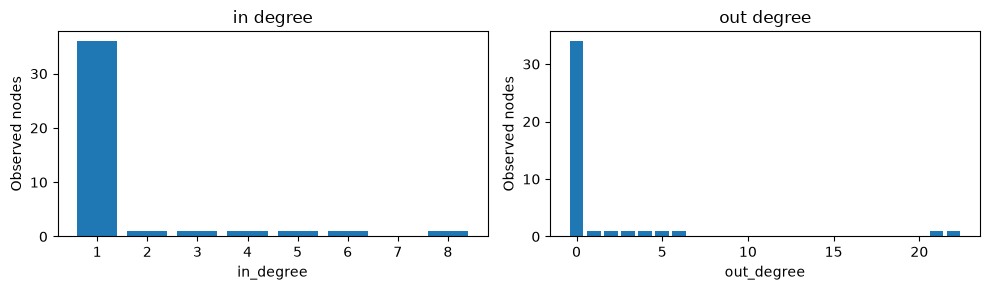

Weak components: 1
Strong components: 35
Reachable from seed (excluding seed): 41


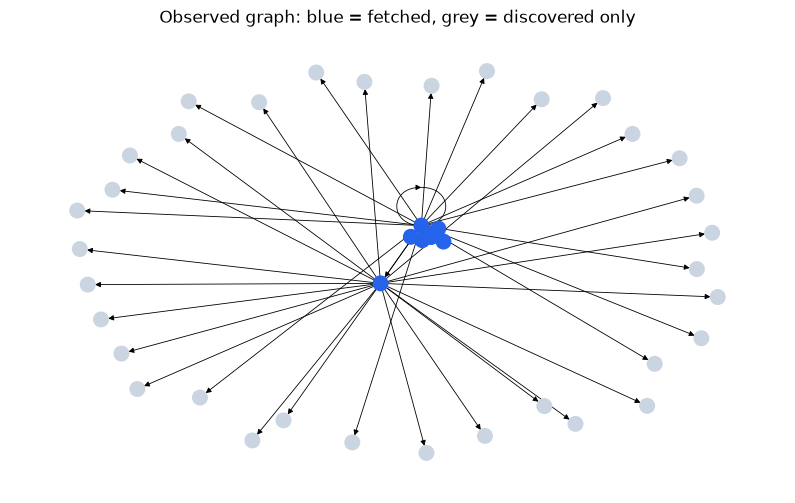

In [18]:
print("Observed graph:", G.number_of_nodes(), "nodes;", G.number_of_edges(), "edges")
print("Fetched-only graph:", H.number_of_nodes(), "nodes;", H.number_of_edges(), "edges")
degree_table = pd.DataFrame([
    {"url": u, "fetched": u in pages, "in_degree": G.in_degree(u), "out_degree": G.out_degree(u)}
    for u in G
])
if not degree_table.empty:
    display(degree_table.sort_values(["in_degree", "url"], ascending=[False, True]).head(8))
    display(degree_table[degree_table.out_degree == 0])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for ax, column in zip(axes, ["in_degree", "out_degree"]):
        counts = degree_table[column].value_counts().sort_index()
        ax.bar(counts.index, counts.values)
        ax.set(xlabel=column, ylabel="Observed nodes", title=column.replace("_", " "))
    plt.tight_layout()
    plt.show()
if G:
    print("Weak components:", nx.number_weakly_connected_components(G))
    print("Strong components:", nx.number_strongly_connected_components(G))
    print("Reachable from seed (excluding seed):", len(nx.descendants(G, normalize_url(SEED, SEED))))
    pos = nx.spring_layout(G, seed=6)
    colors = ["#2563eb" if u in pages else "#cbd5e1" for u in G]
    plt.figure(figsize=(10, 6))
    nx.draw_networkx(G, pos, node_color=colors, node_size=110, with_labels=False,
                     arrows=True, arrowsize=8, width=0.6)
    plt.title("Observed graph: blue = fetched, grey = discovered only")
    plt.axis("off")
    plt.show()

**Answer 6.1:** Why does the home page often receive many links? Is that evidence it is the best book search result? Connect your answer to breadcrumb/navigation links.

*Your answer:* The homepage often receives many incoming links because book detail pages contain breadcrumbs and navigation links that direct users back to the homepage. In our graph, the homepage has the highest observed in-degree of 8, showing that all eight downloaded pages link to it.
However, this does not mean it is the best book search result. A high in-degree indicates navigational importance, not necessarily relevance to a user's search query. Book search results should be ranked based on content relevance rather than navigation links alone.

**Answer 6.2:** Pick an observed sink. Was it fetched? What can you conclude about its real outgoing links? Why would blindly treating every target-only node as dangling affect later PageRank calculations?

*Your answer:* One observed sink is the unfetched book page beginning with **/catalogue/aladdin-a...**, which has an observed in-degree of 1 and out-degree of 0. Since this page was not fetched, we cannot conclude that it has no outgoing links. Its links were simply not observed during our limited crawl.
Blindly treating every target-only node as a dangling page would incorrectly assume it has no outgoing links. This could distort PageRank calculations by redistributing rank from nodes whose actual outgoing links are unknown, producing misleading importance scores.

**Answer 6.3:** Explain weak versus strong connectivity using your graph. If the whole observed graph forms one weak component, does that prove you collected every page on the website?

*Your answer:* Weak connectivity means nodes are connected when edge directions are ignored, while strong connectivity requires nodes to be reachable from one another by following directed edges.
Our observed graph contains 42 nodes, 64 edges, 1 weakly connected component, and 35 strongly connected components. This means all observed nodes are connected when directions are ignored, but many cannot reach one another through directed paths.
Having one weakly connected component does not prove that we collected every page on the website. Our crawler only downloaded 8 pages and discovered additional targets within a restricted scope. Therefore, the connectivity results describe only our observed subgraph, not the entire website.

## Part 7. Reflection and submission (10 min)
Write 4–6 sentences connecting **Week 5 extraction** to **Week 6 discovery**. Explain what the frontier adds, which limit stopped your run, why saved HTML pages differ from IR documents, and one limitation of the graph.

*Your reflection:* In Week 5, we focused on extracting structured book information from HTML pages, while Week 6 extended this process by introducing BFS crawling to discover and manage URLs systematically. The frontier uses a FIFO queue to control crawling order, while the request budget and page-type quotas limit the number of pages explored. Our crawl reached its configured limits of 8 requests, including 2 listing pages and 6 book pages, with all requests successful. Saved HTML pages include both listing and detail pages with navigation content, whereas IR documents contain only book-specific information for searching and indexing. One limitation of our observed graph is that it includes discovered but unfetched pages, meaning their outgoing links remain unknown and the graph cannot represent the complete website structure. This lab demonstrates how web crawling, document extraction, and link analysis work together to support an Information Retrieval system.

**Submit:**
- [ ] `Lab6_<StudentID>.ipynb` with core TODOs and answers completed.
- [ ] `lab6_output/pages.jsonl`, `edges.csv`, `ir_books_corpus.jsonl`, `crawl_metadata.json`.
- [ ] Crawl counters, replay comparison, corpus QA and graph figures in notebook outputs.
- [ ] Week 5 schema/title comparison (or explain that the old export was unavailable).

The optional extensions below are not required for a clean run of the core notebook. For your team project, extend Week 5's source-and-ethics plan with seed URLs, scope, frontier policy, request/depth limits, and graph sampling limitations. Keep the project's own schedule; this notebook adds no new deadline.

## Optional A. Focused scheduling on cached book pages
Use **only cached detail responses** and a budget of 3 saved book pages for both policies. This isolates a scheduling idea; it is **not** a full focused crawl or a whole-site recall measurement. Frontier candidates are already known from our bounded sample.

Choose a few words likely to occur in the cached titles, such as `poetry`, `light`, `science` or `velvet`. Score candidates using their **URL slug only**, before reading the response. Compare FIFO candidate order with descending score. Label a cached page relevant using its **parsed title**, after selecting it. Relevance here is a deliberately simple proxy; explain why it is imperfect.

TODO: produce policy, sampled books, relevant sampled, harvest rate (= relevant / sampled). Guard empty denominators. If the scores tie or all relevance labels are zero, report that result; do not invent an improvement. Recall is only meaningful relative to the explicitly defined cached candidate set, never the whole website.

In [19]:
import json
import re
from pathlib import Path
from urllib.parse import urlsplit

import pandas as pd

focus_terms = {"light", "velvet", "history", "poetry"}
focus_budget = 3
cached_responses = globals().get("response_cache", {})
saved_titles = {}

if cached_responses and "pages" in globals():
    focus_candidates = [
        url for url in pages if page_kind(url) == "book" and url in cached_responses
    ]
    print("Relevance source: titles parsed from cached book HTML")
else:
    focus_output = Path("lab6_output")
    with (focus_output / "ir_books_corpus.jsonl").open(encoding="utf-8") as corpus_file:
        saved_titles = {row["url"]: row["title"] for row in map(json.loads, corpus_file)}
    with (focus_output / "pages.jsonl").open(encoding="utf-8") as pages_file:
        focus_candidates = [
            row["url"] for row in map(json.loads, pages_file)
            if row["kind"] == "book" and row["url"] in saved_titles
        ]
    print("Relevance source: original parsed titles from the saved crawl exports")


def slug_score(url):
    slug = urlsplit(url).path.split("/")[-2].rsplit("_", 1)[0]
    return len(focus_terms.intersection(re.findall(r"[a-z]+", slug.lower())))


def selected_title(url):
    if url in saved_titles:
        return saved_titles[url]
    soup = BeautifulSoup(cached_responses[url].content, "html.parser")
    return parse_book(soup, url)["title"]


# Python's stable sort keeps FIFO order when scores tie.
focus_policies = {
    "FIFO": focus_candidates,
    "URL score": sorted(focus_candidates, key=slug_score, reverse=True),
}
focus_results = []
for policy, candidates in focus_policies.items():
    titles = [selected_title(url) for url in candidates[:focus_budget]]
    relevant = sum(
        bool(focus_terms.intersection(re.findall(r"[a-z]+", title.lower())))
        for title in titles
    )
    focus_results.append({
        "Policy": policy,
        "Sample size": len(titles),
        "Sampled books": titles,
        "Relevant sampled": relevant,
        "Harvest rate": relevant / len(titles) if titles else None,
    })

print("Saved book candidates:", len(focus_candidates))
display(pd.DataFrame(focus_results))

Relevance source: original parsed titles from the saved crawl exports
Saved book candidates: 6


,Policy,Sample size,Sampled books,Relevant sampled,Harvest rate
0,FIFO,3,"[A Light in the Attic, Tipping the Velvet, Sou...",2,0.666667
1,URL score,3,"[A Light in the Attic, Tipping the Velvet, Sap...",3,1.000000


For this sample, I used **light**, **velvet**, **history** and **poetry**. The FIFO policy selected *A Light in the Attic*, *Tipping the Velvet* and *Soumission*, giving 2 relevant books out of 3 (66.7%). URL scoring moved *Sapiens: A Brief History of Humankind* ahead of *Soumission*, giving 3 out of 3 (100%). The three positive scores tied, so they kept their original FIFO order.

A title keyword only approximates relevance. *A Light in the Attic* is a poetry book, but neither its slug nor its title contains **poetry**. A slug also cannot show whether a keyword describes the book's main topic. These results describe the six saved candidates. After a kernel restart, the cell uses the original parsed titles in the exports and preserves the order from `pages.jsonl`.

## Optional B. Corpus → inverted index
Load `lab6_output/ir_books_corpus.jsonl` and reuse your earlier course preprocessing and AND search. Index `record["text"]` (already title + description) rather than navigation-filled HTML text.

TODO: map each term to unique sorted `doc_id` postings; report vocabulary size, document frequencies, and three test queries. Apply **exactly the same** preprocessing to documents and queries. State how the small sample limits search coverage.

In [20]:
import json
import re
from collections import defaultdict
from pathlib import Path

import pandas as pd

# Same preprocessing as Weeks 2 and 3.
STOP_WORDS = set("""a an the is are was were be been being of to in on at for with and or not
this that these those it its as by from into over under about than then so if but""".split())
SUFFIXES = ["ational", "tional", "alize", "ation", "ative", "fulness", "ousness",
            "iveness", "ing", "ies", "ied", "ly", "ed", "es", "s"]


def simple_stem(word):
    for suffix in SUFFIXES:
        if word.endswith(suffix) and len(word) - len(suffix) >= 3:
            return word[:-len(suffix)]
    return word


def preprocess(text):
    tokens = re.findall(r"[a-z]+", text.lower())
    return [simple_stem(token) for token in tokens if token not in STOP_WORDS]


with Path("lab6_output/ir_books_corpus.jsonl").open(encoding="utf-8") as corpus_file:
    index_records = {row["doc_id"]: row for row in map(json.loads, corpus_file)}

posting_sets = defaultdict(set)
for doc_id, record in index_records.items():
    for term in preprocess(record["text"]):
        posting_sets[term].add(doc_id)

inverted_index = {term: sorted(doc_ids) for term, doc_ids in sorted(posting_sets.items())}
document_frequencies = {term: len(doc_ids) for term, doc_ids in inverted_index.items()}


def boolean_and(query):
    terms = set(preprocess(query))
    if not terms:
        return []
    postings = sorted((inverted_index.get(term, []) for term in terms), key=len)
    matches = set(postings[0])
    for posting in postings[1:]:
        matches.intersection_update(posting)
    return sorted(matches)


print("Indexed documents:", len(index_records))
print("Vocabulary size:", len(inverted_index))
frequency_table = pd.Series(document_frequencies, name="Document frequency", dtype=int)
display(frequency_table.sort_values(ascending=False, kind="stable").head(10).to_frame())

query_results = []
for query in ["THE LIGHT IN THE ATTIC", "music", "velvet humankind"]:
    terms = dict.fromkeys(preprocess(query))
    matches = boolean_and(query)
    query_results.append({
        "Query": query,
        "Query terms and document frequencies": {
            term: document_frequencies.get(term, 0) for term in terms
        },
        "Matching doc IDs": matches,
        "Matching titles": [index_records[doc_id]["title"] for doc_id in matches],
    })
display(pd.DataFrame(query_results))

Indexed documents: 6
Vocabulary size: 525


,Document frequency
more,6
s,6
girl,3
her,3
life,3
other,3
she,3
where,3
world,3
ago,2


,Query,Query terms and document frequencies,Matching doc IDs,Matching titles
0,THE LIGHT IN THE ATTIC,"{'light': 2, 'attic': 1}",[b828157e0e87],[A Light in the Attic]
1,music,{'music': 2},"[6e35640b1d28, d21e642d904a]","[The Requiem Red, Tipping the Velvet]"
2,velvet humankind,"{'velvet': 1, 'humankind': 1}",[],[]


**Search coverage.** The index can retrieve only the six successfully crawled books and the terms in their titles and descriptions. The query `velvet humankind` illustrates the AND rule because both terms occur in the index, but they occur in different books. Books outside the crawl and topics absent from the indexed text are outside this search sample.

## Optional C. Extend the real Week 5 Scrapy project
Keep `bookcrawler` and add a new spider named `books_graph` alongside `books.py`. Reuse `parse_book()` selectors and the two-listing boundary; do not replace the project with the old wiki `runspider` exercise.

Map the concepts first:

| Manual crawler | Scrapy project |
|---|---|
| Frontier | scheduler and queued Requests |
| `seen` | request duplicate filter (request fingerprints) |
| Normalization | explicit site-specific URL policy before scheduling |
| Depth | `DEPTH_LIMIT` |
| Delay/robots | `DOWNLOAD_DELAY`, `ROBOTSTXT_OBEY` |
| Saved book dict | item yielded by `parse_book()` |
| Export | feed exporter |

For an optional live run, retain Week 5's settings, use one concurrent request, and enforce **two listing admissions and six detail admissions** in spider code before yielding requests. Keep `DEPTH_LIMIT=2`; use breadth-first scheduler settings if comparing order. Scrapy's default scheduling is not the manual FIFO implementation.

`CLOSESPIDER_PAGECOUNT` counts responses and can overshoot because of requests in flight. It is **not an exact request-attempt budget** and is not equivalent to our loop's `max_requests`. Do not use it as your only boundary. Use a different output filename so Week 5 exports survive.

**Written task (no new crawl required):** explain how the same extraction callback can serve a different scheduling policy, and why Scrapy's duplicate filter cannot infer that arbitrary query parameters are tracking.

**References:** [Books to Scrape](https://books.toscrape.com/) · [Requests quickstart](https://requests.readthedocs.io/en/latest/user/quickstart/) · [Scrapy settings](https://docs.scrapy.org/en/latest/topics/settings.html) · [Scrapy close-spider extension](https://docs.scrapy.org/en/latest/topics/extensions.html#module-scrapy.extensions.closespider).

**Written answer.** In Week 5, `parse_book()` extracts fields from the response it receives. The new `books_graph` spider inherits that callback and decides separately which book requests to schedule. It admits the seed and the second listing, queues up to six distinct detail URLs, and uses depth priority and FIFO queues with one concurrent request. Changing the scheduling order affects when a response reaches `parse_book()`; the callback still extracts the same fields. The spider inherits the project's robots and download-delay settings. Retries and automatic redirects are disabled so one admitted page does not generate extra page attempts. [Scrapy settings](https://docs.scrapy.org/en/latest/topics/settings.html)

Scrapy's duplicate filter compares request fingerprints. Fingerprinting canonicalizes URL form without knowing whether a query key measures a campaign or selects different content. The spider removes `utm` and `utm_*` keys and checks the resulting URL against the lab's scope before it spends an admission. A key such as `page` survives normalization, and the scope check excludes that query-bearing URL. [Scrapy request fingerprints](https://docs.scrapy.org/en/latest/topics/request-response.html#request-fingerprints)

The new spider is in `W5/bookcrawler/bookcrawler/spiders/books_graph.py`. If you choose to run it later, use the following command from `W5/bookcrawler`. It writes to a separate Week 6 export.

```bash
scrapy crawl books_graph -O ../../W6/lab6_output/books_graph.jsonl
```